In [1]:
import pandas as pd

sales_data_deduped = pd.read_csv(
    r"D:\Portfolio\retail-online-analysis\data\sales_data_deduped.csv",
    dtype={'InvoiceNo': 'string'}
)

sales_data_deduped['InvoiceDate'] = pd.to_datetime(sales_data_deduped['InvoiceDate'])
sales_data_deduped['CustomerID'] = sales_data_deduped['CustomerID'].astype('Int64')

sales_data_deduped['Revenue'] = sales_data_deduped['Quantity'] * sales_data_deduped['UnitPrice']

In [2]:
# Data types
print(sales_data_deduped.dtypes)

InvoiceNo              string
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID              Int64
Country                   str
Revenue               float64
dtype: object


In [3]:
# Convert the 'InvoiceDate' column to datetime format
sales_data_deduped['InvoiceDate'] = pd.to_datetime(
    sales_data_deduped['InvoiceDate']
)

sales_data_deduped['InvoiceDate'].dtype

dtype('<M8[us]')

In [4]:
# 1. Count the revenue (Quantity * UnitPrice) for each transaction
sales_data_deduped['Revenue'] = sales_data_deduped['Quantity'] * sales_data_deduped['UnitPrice']
print(sales_data_deduped.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  Revenue  
0 2010-12-01 08:26:00       2.55       17850  United Kingdom    15.30  
1 2010-12-01 08:26:00       3.39       17850  United Kingdom    20.34  
2 2010-12-01 08:26:00       2.75       17850  United Kingdom    22.00  
3 2010-12-01 08:26:00       3.39       17850  United Kingdom    20.34  
4 2010-12-01 08:26:00       3.39       17850  United Kingdom    20.34  


In [5]:
print(sales_data_deduped.tail())

       InvoiceNo StockCode                      Description  Quantity  \
524873    581587     22613      PACK OF 20 SPACEBOY NAPKINS        12   
524874    581587     22899     CHILDREN'S APRON DOLLY GIRL          6   
524875    581587     23254    CHILDRENS CUTLERY DOLLY GIRL          4   
524876    581587     23255  CHILDRENS CUTLERY CIRCUS PARADE         4   
524877    581587     22138    BAKING SET 9 PIECE RETROSPOT          3   

               InvoiceDate  UnitPrice  CustomerID Country  Revenue  
524873 2011-12-09 12:50:00       0.85       12680  France    10.20  
524874 2011-12-09 12:50:00       2.10       12680  France    12.60  
524875 2011-12-09 12:50:00       4.15       12680  France    16.60  
524876 2011-12-09 12:50:00       4.15       12680  France    16.60  
524877 2011-12-09 12:50:00       4.95       12680  France    14.85  


In [6]:
# 2. Sum the revenue rounded to 2 decimal places
total_revenue = sales_data_deduped['Revenue'].sum()
print(f"Total Revenue: {total_revenue:.2f}")

Total Revenue: 10642110.80


In [7]:
# 3. Monthly revenue
monthly_revenue = sales_data_deduped.groupby(
    sales_data_deduped['InvoiceDate'].dt.to_period('M')
)['Revenue'].sum().round(2)
print("Monthly Revenue:", monthly_revenue)

Monthly Revenue: InvoiceDate
2010-12     821452.73
2011-01     689811.61
2011-02     522545.56
2011-03     716215.26
2011-04     536968.49
2011-05     769296.61
2011-06     760547.01
2011-07     718076.12
2011-08     757841.38
2011-09    1056435.19
2011-10    1151263.73
2011-11    1503866.78
2011-12     637790.33
Freq: M, Name: Revenue, dtype: float64


In [8]:
# 4. Convert Monthly revenue to DataFrame
monthly_revenue_df = monthly_revenue.reset_index().rename(columns={'InvoiceDate': 'InvoiceMonth', 'Revenue': 'Total Revenue'})
print(monthly_revenue_df)

   InvoiceMonth  Total Revenue
0       2010-12      821452.73
1       2011-01      689811.61
2       2011-02      522545.56
3       2011-03      716215.26
4       2011-04      536968.49
5       2011-05      769296.61
6       2011-06      760547.01
7       2011-07      718076.12
8       2011-08      757841.38
9       2011-09     1056435.19
10      2011-10     1151263.73
11      2011-11     1503866.78
12      2011-12      637790.33


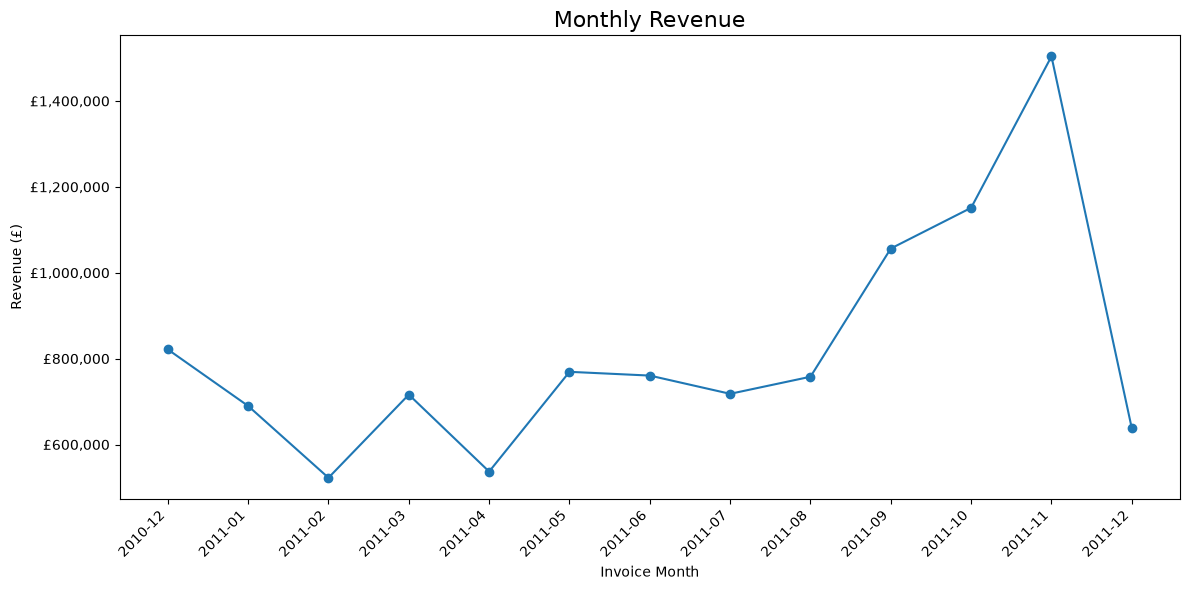

In [9]:
# 5. Visualize the monthly revenue with line chart
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue_df['InvoiceMonth'].astype(str),
    monthly_revenue_df['Total Revenue'],
    marker='o'
)

plt.title('Monthly Revenue', fontsize=16)
plt.xlabel('Invoice Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45, ha='right')
plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter('£{x:,.0f}')
)

plt.tight_layout()
plt.show()

# Summary

The monthly revenue analysis was conducted using the cleaned dataset, sales_data_deduped.csv. The analysis revealed the following:
- **Total revenue**: £10,642,110.80.
- **Highest-revenue month**: November 2011, with £1,503,866.78.
- **Lowest-revenue month**: February 2011, with £522,545.56.